# Лабораторна робота №3. Оцінювання параметрів регресійних рівнянь
**Варіант 13**

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import least_squares
from IPython.display import display

pd.set_option('display.float_format', '{:.4f}'.format)

In [53]:
rtsmm = np.loadtxt('Data/RTSmm.txt')
rts2007 = np.loadtxt('Data/2007rts1.txt')

print('RTSmm:', len(rtsmm), 'значень')
print('2007rts1:', len(rts2007), 'значень')

RTSmm: 178 значень
2007rts1: 248 значень


## Частина 1. Статистика Дарбіна–Уотсона

$$
DW=\frac{\sum_{t=2}^{N}(\varepsilon_t-\varepsilon_{t-1})^2}{\sum_{t=1}^{N}\varepsilon_t^2},\qquad DW\in[0;4]
$$

In [54]:
def DW(e):
    return np.sum(np.diff(e) ** 2) / np.sum(e ** 2)


e_test = np.loadtxt('example_for_DW.txt')
print('DW =', round(DW(e_test), 5))

DW = 1.22881


## Функції з ЛР №2: ковзні середні, АКФ, ЧАКФ

$$
SMA(k)=\frac{1}{N}\sum_{i=1}^{N}y(k-i+1),\qquad
EMA(k)=\frac{\sum_{i=1}^{N}w_i\, y(k-N+i)}{\sum_{i=1}^{N}w_i},\qquad
w_i=(1-\alpha)^{N-i+1},\ \alpha=\frac{2}{N+1}
$$

In [55]:
def SMA(x, n):
    x = np.asarray(x, dtype=float)
    result = np.full(len(x), np.nan)
    for t in range(n - 1, len(x)):
        result[t] = np.mean(x[t-n+1:t+1])
    return result


def EMA(x, n):
    x = np.asarray(x, dtype=float)
    alpha = 2 / (n + 1)
    weights = (1 - alpha) ** np.arange(n, 0, -1)
    weights = weights / weights.sum()
    result = np.full(len(x), np.nan)
    for t in range(n - 1, len(x)):
        result[t] = np.sum(x[t-n+1:t+1] * weights)
    return result


def ACF(x, max_lag):
    n = len(x)
    mean = np.mean(x)
    variance = np.sum((x - mean) ** 2) / (n - 1)
    result = [1.0]
    for s in range(1, max_lag + 1):
        numerator = np.sum((x[s:] - mean) * (x[:-s] - mean))
        result.append(numerator / ((n - 1) * variance))
    return np.array(result)


def PACF(r):
    result = [1.0]
    phi = np.array([])
    for k in range(1, len(r)):
        numerator = r[k] - np.dot(phi, r[1:k][::-1])
        denominator = 1 - np.dot(phi, r[1:k])
        new_phi = numerator / denominator
        phi = np.append(phi - new_phi * phi[::-1], new_phi)
        result.append(new_phi)
    return np.array(result)


def moving_average(series, kind, n):
    values = SMA(series.values, n) if kind == 'SMA' else EMA(series.values, n)
    return pd.Series(values, index=series.index)

## Допоміжні функції

$$
S=\frac{1}{N}\sum\left(\frac{y-\bar y}{\hat\sigma}\right)^3,\quad
K=\frac{1}{N}\sum\left(\frac{y-\bar y}{\hat\sigma}\right)^4,\quad
JB=\frac{N}{6}\left(S^2+\frac{(K-3)^2}{4}\right)\sim\chi^2(2)
$$

де $\hat\sigma$ — зміщена оцінка (ділення на $N$), а Std. Dev. — незміщена (ділення на $N-1$).

In [56]:
THRESHOLD = 0.3
LAGS = 12


def describe(x, name):
    x = np.asarray(x, dtype=float)
    n = len(x)
    mean = x.mean()
    sigma = x.std(ddof=0)
    S = np.mean(((x - mean) / sigma) ** 3)
    K = np.mean(((x - mean) / sigma) ** 4)
    JB = n / 6 * (S ** 2 + (K - 3) ** 2 / 4)
    return pd.Series({
        'Mean': mean, 'Median': np.median(x), 'Maximum': x.max(), 'Minimum': x.min(),
        'Std. Dev.': x.std(ddof=1), 'Skewness': S, 'Kurtosis': K,
        'Jarque-Bera': JB, 'Probability': 1 - stats.chi2.cdf(JB, 2),
        'Sum': x.sum(), 'Sum Sq. Dev.': np.sum((x - mean) ** 2), 'Observations': n
    }, name=name)


def correlogram(x, title, lags=LAGS, plot=True):
    x = pd.Series(x).dropna().values
    r = ACF(x, lags)
    phi = PACF(r)
    table = pd.DataFrame({'ACF': r[1:], 'PACF': phi[1:]}, index=range(1, lags + 1)).T
    display(table.round(4))
    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(11, 3))
        for a, values, label in [(ax[0], r[1:], 'АКФ'), (ax[1], phi[1:], 'ЧАКФ')]:
            a.bar(range(1, lags + 1), values)
            a.axhline(THRESHOLD, color='r', ls='--')
            a.axhline(-THRESHOLD, color='r', ls='--')
            a.set_title(label + " для " + title)
            a.set_xlabel('лаг')
            a.grid()
        plt.tight_layout()
        plt.show()
    return phi


def choose_order(phi, threshold=THRESHOLD, min_order=1):
    significant = [k for k in range(1, len(phi)) if abs(phi[k]) > threshold]
    order = max(significant) if significant else 0
    return max(order, min_order), significant

## Метод найменших квадратів

$$
R^2=1-\frac{SSR}{\sum(y-\bar y)^2},\quad
\ell=-\frac{T}{2}\left(1+\ln 2\pi+\ln\frac{SSR}{T}\right),\quad
AIC=-\frac{2\ell}{T}+\frac{2k}{T},\quad
SC=-\frac{2\ell}{T}+\frac{k\ln T}{T}
$$

In [57]:
def make_result(names, coef, se, Y, resid, index):
    T, k = len(Y), len(coef)
    SSR = np.sum(resid ** 2)
    TSS = np.sum((Y - Y.mean()) ** 2)
    R2 = 1 - SSR / TSS
    loglik = -T / 2 * (1 + np.log(2 * np.pi) + np.log(SSR / T))
    t = coef / se
    return {
        'coef': pd.Series(coef, index=names), 'se': pd.Series(se, index=names),
        't': pd.Series(t, index=names),
        'p': pd.Series(2 * (1 - stats.t.cdf(np.abs(t), T - k)), index=names),
        'R2': R2, 'adjR2': 1 - (1 - R2) * (T - 1) / (T - k),
        'SE': np.sqrt(SSR / (T - k)), 'SSR': SSR, 'loglik': loglik,
        'mean_dep': Y.mean(), 'sd_dep': Y.std(ddof=1),
        'AIC': -2 * loglik / T + 2 * k / T,
        'SC': -2 * loglik / T + k * np.log(T) / T,
        'DW': DW(resid), 'T': T, 'k': k,
        'resid': pd.Series(resid, index=index), 'index': index
    }


def ls(y, X):
    data = pd.concat([y.rename('__y'), X], axis=1).dropna()
    Y = data['__y'].values
    Xm = data[X.columns].values
    coef = np.linalg.lstsq(Xm, Y, rcond=None)[0]
    resid = Y - Xm @ coef
    s2 = np.sum(resid ** 2) / (len(Y) - Xm.shape[1])
    se = np.sqrt(np.diag(s2 * np.linalg.inv(Xm.T @ Xm)))
    return make_result(list(X.columns), coef, se, Y, resid, data.index)


def lags(x, name, orders):
    return {f'{name}(-{i})': x.shift(i) for i in orders}


def show(res, title=''):
    print(f'{title}   (T = {res["T"]}, k = {res["k"]})')
    display(pd.DataFrame({'Coefficient': res['coef'], 'Std. Error': res['se'],
                          't-Statistic': res['t'], 'Prob.': res['p']}).round(4))
    display(pd.Series({
        'R-squared': res['R2'], 'Adjusted R-squared': res['adjR2'],
        'S.E. of regression': res['SE'], 'Sum squared resid': res['SSR'],
        'Log likelihood': res['loglik'], 'Mean dependent var': res['mean_dep'],
        'S.D. dependent var': res['sd_dep'], 'Akaike info criterion': res['AIC'],
        'Schwarz criterion': res['SC'], 'Durbin-Watson stat': res['DW']
    }).round(4).to_frame('Значення'))

## АРКС(p,q) зі стандартним КС

$$
y(k)=a_0+\sum_{i=1}^{p}a_i\,y(k-i)+\varepsilon(k)+\sum_{j=1}^{q}\theta_j\,\varepsilon(k-j)
$$

In [58]:
def arma_cls(y, p, q):
    y = np.asarray(y, dtype=float)
    n = len(y)

    def errors(params):
        a0, a, b = params[0], params[1:p+1], params[p+1:]
        e = np.zeros(n)
        for t in range(p, n):
            e[t] = y[t] - a0 - np.dot(a, y[t-p:t][::-1])
            for j in range(1, q + 1):
                if t - j >= p:
                    e[t] -= b[j-1] * e[t-j]
        return e[p:]

    X0 = np.column_stack([np.ones(n - p)] + [y[p-i:n-i] for i in range(1, p + 1)])
    start = np.r_[np.linalg.lstsq(X0, y[p:], rcond=None)[0], np.zeros(q)]
    fit = least_squares(errors, start)
    resid = fit.fun
    J = fit.jac
    s2 = np.sum(resid ** 2) / (len(resid) - len(start))
    se = np.sqrt(np.diag(s2 * np.linalg.inv(J.T @ J)))
    names = ['c'] + [f'y(-{i})' for i in range(1, p+1)] + [f'e(-{j})' for j in range(1, q+1)]
    return make_result(names, fit.x, se, y[p:], resid, pd.RangeIndex(p, n))

In [59]:
def term(col):
    var, lag = col.split('(-')
    return f'{var}(k−{lag[:-1]})'


def num(v):
    return f'{abs(v):.4f}'.replace('.', ',')


def equation(res, extra=''):
    parts = []
    for col, v in res['coef'].items():
        if col == 'c':
            parts.append(('−' if v < 0 else '') + num(v))
        else:
            parts.append(f"{'−' if v < 0 else '+'} {num(v)}·{term(col)}")
    return 'y(k) = ' + ' '.join(parts) + (' ' + extra if extra else '')


def add_row(rows, group, label, res, y, eq):
    y_s = y.loc[res['index']]
    rows.append({
        'Група': group,
        'Модель': label,
        'R-squared': res['R2'],
        'Sum squared resid': res['SSR'],
        'Akaike': res['AIC'],
        'Durbin-Watson': res['DW'],
        'Рівняння': eq, 
        'res': res
    })


def ma_weights(q):
    # b_i = (1-α)^i / Σ(1-α)^j,  α = 2/(q+1);  при q = 1 формула дає 0/0, тому b1 = 1
    if q == 1:
        return np.array([1.0])
    alpha = 2 / (q + 1)
    w = (1 - alpha) ** np.arange(1, q + 1)
    return w / w.sum()


MA_LIST = [('SMA', 5), ('SMA', 10), ('EMA', 5), ('EMA', 10)]
MA_NAME = {'SMA': 'просте', 'EMA': 'експоненційне'}

## Алгоритм підбору рівняння

In [60]:
def analyze(values, name):
    y = pd.Series(values, dtype=float)
    rows = []

    phi_y = correlogram(y, name)
    p, sig = choose_order(phi_y)

    X_ar = pd.DataFrame({'c': 1.0, **lags(y, 'y', range(1, p + 1))})
    ar = ls(y, X_ar)
    g1 = 'КС по залишках АР(p)'
    add_row(rows, g1, f'АР({p})', ar, y, equation(ar))

    resid = ar['resid'].reindex(y.index)
    phi_e = correlogram(resid, f'залишків АР({p})')
    q, sig_q = choose_order(phi_e)

    arma = arma_cls(y, p, q)
    add_row(rows, g1, f'АРКС({p},{q}) - КС системи (ma)', arma, y, equation(arma, '+ e(k)'))

    for kind, N in MA_LIST:
        ma = moving_average(resid, kind, N)
        X = pd.DataFrame({'c': 1.0, **lags(y, 'y', range(1, p + 1)), **lags(ma, 'ma', range(1, q + 1))})
        res = ls(y - ma, X)
        add_row(rows, g1, f'АРКС({p},{q}) - власне {MA_NAME[kind]} КС, N={N}', res, y,
                equation(res, '+ ma(k)'))

    rows1, rows2, pacf_ma = [], [], {}
    for kind, N in MA_LIST:
        ma = moving_average(y, kind, N)
        phi_ma = PACF(ACF(ma.dropna().values, LAGS))
        pacf_ma[f'{kind}({N})'] = phi_ma[1:]
        q_ma, _ = choose_order(phi_ma)
        label = f'АРКС({p},{q_ma}) - власне {MA_NAME[kind]} КС по y, N={N}'

        # підхід 1
        b = ma_weights(q_ma)
        y1 = y - ma - sum(b[j-1] * ma.shift(j) for j in range(1, q_ma + 1))
        res1 = ls(y1, X_ar)
        extra = '+ ma(k) ' + ' '.join(f'+ {num(b[j-1])}·ma(k−{j})' for j in range(1, q_ma + 1))
        add_row(rows1, 'КС по y, підхід 1 (власні b_j)', label, res1, y, equation(res1, extra))

        # підхід 2
        X = pd.DataFrame({'c': 1.0, **lags(y, 'y', range(1, p + 1)), **lags(ma, 'ma', range(1, q_ma + 1))})
        res2 = ls(y - ma, X)
        add_row(rows2, 'КС по y, підхід 2 (b_j оцінюються)', label, res2, y, equation(res2, '+ ma(k)'))

    table_pacf = pd.DataFrame(pacf_ma, index=range(1, LAGS + 1)).T
    display(table_pacf.round(4))

    table = pd.DataFrame(rows + rows1 + rows2)
    table.index = range(1, len(table) + 1)
    return table


def table1(table):
    return table[['Група', 'Модель', 'R-squared', 'Sum squared resid', 'Akaike', 'Durbin-Watson']].round(4)


def table2(table):
    return table[['Група', 'Модель', 'Рівняння']].style.set_properties(**{'text-align': 'left'})


def best_model(table):
    return table['Akaike'].idxmin()

## Частина 2. Побудова адекватного рівняння для опису процесу

### Ряд RTSmm

**Описова статистика**

,RTSmm
Mean,359.1520
Median,374.0250
Maximum,442.9900
Minimum,194.2700
Std. Dev.,57.0780
Skewness,-1.1278
Kurtosis,3.5758
Jarque-Bera,40.1916
Probability,0.0000
Sum,63929.0500


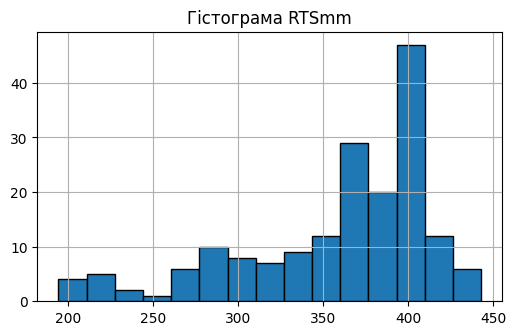

In [61]:
display(describe(rtsmm, 'RTSmm').round(4).to_frame())

plt.figure(figsize=(6, 3.5))
plt.hist(rtsmm, bins=15, edgecolor='black')
plt.title('Гістограма RTSmm')
plt.grid()
plt.show()

,1,2,3,4,5,6,7,8,9,10,11,12
ACF,0.9683,0.9342,0.8993,0.8636,0.8330,0.8027,0.7682,0.7331,0.6998,0.6706,0.6404,0.6120
PACF,0.9683,-0.0553,-0.0289,-0.0305,0.0638,-0.0174,-0.0875,-0.0259,0.0183,0.0481,-0.0529,0.0093


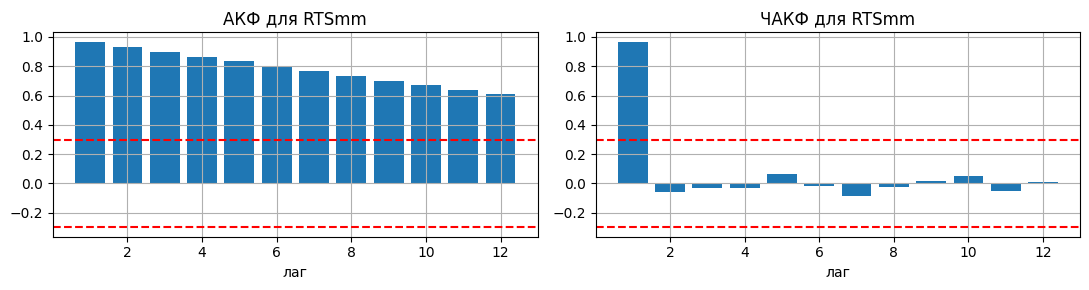

,1,2,3,4,5,6,7,8,9,10,11,12
ACF,0.1879,-0.0015,-0.0071,-0.1270,0.1024,0.0704,0.0128,0.0441,-0.0619,0.0325,0.1496,-0.0326
PACF,0.1879,-0.0382,0.0004,-0.1305,0.1599,0.0133,0.0033,0.0230,-0.0445,0.0576,0.1270,-0.0867


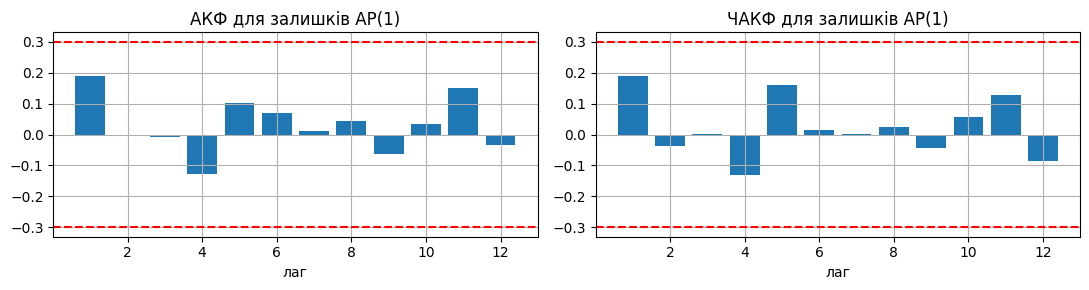

,1,2,3,4,5,6,7,8,9,10,11,12
SMA(5),0.9723,-0.0656,-0.0627,-0.0443,-0.0152,-0.0073,-0.0200,0.0067,0.0148,0.0176,0.0069,0.0078
SMA(10),0.9721,-0.0486,-0.0357,-0.0248,-0.0123,-0.0157,-0.0183,-0.0090,-0.0077,-0.0092,-0.0018,0.0036
EMA(5),0.9723,-0.0761,-0.0548,-0.0296,0.0019,-0.0198,-0.0383,-0.0031,0.0136,0.0155,-0.0012,0.0239
EMA(10),0.9725,-0.0555,-0.0429,-0.0278,-0.0137,-0.0230,-0.0274,-0.0045,0.0064,0.0050,-0.0003,0.0118


In [62]:
t_rtsmm = analyze(rtsmm, 'RTSmm')

In [63]:
display(table1(t_rtsmm))

,Група,Модель,R-squared,Sum squared resid,Akaike,Durbin-Watson
1,КС по залишках АР(p),АР(1),0.9844,8991.1265,6.7883,1.6205
2,КС по залишках АР(p),"АРКС(1,1) - КС системи (ma)",0.9850,8653.8047,6.7614,2.0019
3,КС по залишках АР(p),"АРКС(1,1) - власне просте КС, N=5",0.9892,6040.9822,6.4316,1.8119
4,КС по залишках АР(p),"АРКС(1,1) - власне просте КС, N=10",0.9881,6555.3999,6.5439,1.5989
5,КС по залишках АР(p),"АРКС(1,1) - власне експоненційне КС, N=5",0.9940,3327.8614,5.8354,1.8177
6,КС по залишках АР(p),"АРКС(1,1) - власне експоненційне КС, N=10",0.9910,4980.5911,6.2691,1.6353
7,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне просте КС по y, N=5",0.9106,41538.0377,8.3421,0.3512
8,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне просте КС по y, N=10",0.7461,94887.0152,9.1982,0.1389
9,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне експоненційне КС по y, N=5",0.9634,17926.8045,7.5018,0.4263
10,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне експоненційне КС по y, N=10",0.8821,48772.6210,8.5326,0.2120


In [64]:
display(table2(t_rtsmm))

,Група,Модель,Рівняння
1,КС по залишках АР(p),АР(1),"y(k) = −6,9158 + 1,0165·y(k−1)"
2,КС по залишках АР(p),"АРКС(1,1) - КС системи (ma)","y(k) = −5,8024 + 1,0135·y(k−1) + 0,2020·e(k−1) + e(k)"
3,КС по залишках АР(p),"АРКС(1,1) - власне просте КС, N=5","y(k) = −6,1591 + 1,0145·y(k−1) − 0,7098·ma(k−1) + ma(k)"
4,КС по залишках АР(p),"АРКС(1,1) - власне просте КС, N=10","y(k) = −5,2217 + 1,0124·y(k−1) − 0,7180·ma(k−1) + ma(k)"
5,КС по залишках АР(p),"АРКС(1,1) - власне експоненційне КС, N=5","y(k) = −6,2870 + 1,0148·y(k−1) − 0,5221·ma(k−1) + ma(k)"
6,КС по залишках АР(p),"АРКС(1,1) - власне експоненційне КС, N=10","y(k) = −5,4946 + 1,0131·y(k−1) − 0,6311·ma(k−1) + ma(k)"
7,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне просте КС по y, N=5","y(k) = −47,9826 − 0,8779·y(k−1) + ma(k) + 1,0000·ma(k−1)"
8,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне просте КС по y, N=10","y(k) = −111,1291 − 0,7134·y(k−1) + ma(k) + 1,0000·ma(k−1)"
9,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне експоненційне КС по y, N=5","y(k) = −28,8229 − 0,9269·y(k−1) + ma(k) + 1,0000·ma(k−1)"
10,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне експоненційне КС по y, N=10","y(k) = −71,2701 − 0,8164·y(k−1) + ma(k) + 1,0000·ma(k−1)"


**Найкраща модель для RTSmm**

In [65]:
best_rtsmm = best_model(t_rtsmm)
show(t_rtsmm.loc[best_rtsmm, 'res'], t_rtsmm.loc[best_rtsmm, 'Модель'])

АРКС(1,1) - власне експоненційне КС, N=5   (T = 172, k = 3)


,Coefficient,Std. Error,t-Statistic,Prob.
c,-6.2870,2.2570,-2.7856,0.0060
y(-1),1.0148,0.0062,163.7269,0.0000
ma(-1),-0.5221,0.0867,-6.0201,0.0000


,Значення
R-squared,0.9940
Adjusted R-squared,0.9940
S.E. of regression,4.4375
Sum squared resid,3327.8614
Log likelihood,-498.8402
Mean dependent var,358.8474
S.D. dependent var,57.1450
Akaike info criterion,5.8354
Schwarz criterion,5.8902
Durbin-Watson stat,1.8177


### Ряд 2007rts1

**Описова статистика**

,2007rts1
Mean,1981.8226
Median,1929.9950
Maximum,2359.8500
Minimum,1724.6900
Std. Dev.,153.7125
Skewness,0.7068
Kurtosis,2.4039
Jarque-Bera,24.3184
Probability,0.0000
Sum,491492.0100


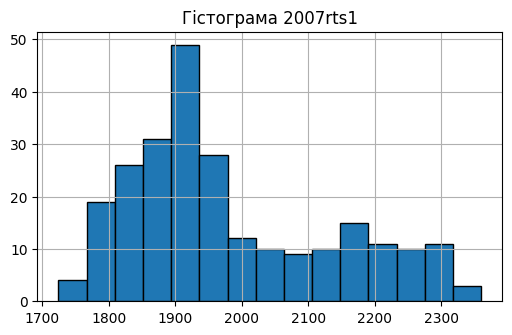

In [66]:
display(describe(rts2007, '2007rts1').round(4).to_frame())

plt.figure(figsize=(6, 3.5))
plt.hist(rts2007, bins=15, edgecolor='black')
plt.title('Гістограма 2007rts1')
plt.grid()
plt.show()

,1,2,3,4,5,6,7,8,9,10,11,12
ACF,0.9749,0.9479,0.9218,0.8961,0.8696,0.8479,0.8240,0.8014,0.7761,0.7522,0.7267,0.7016
PACF,0.9749,-0.0495,0.0042,-0.0063,-0.0294,0.0848,-0.0661,0.0199,-0.0675,0.0134,-0.0380,-0.0146


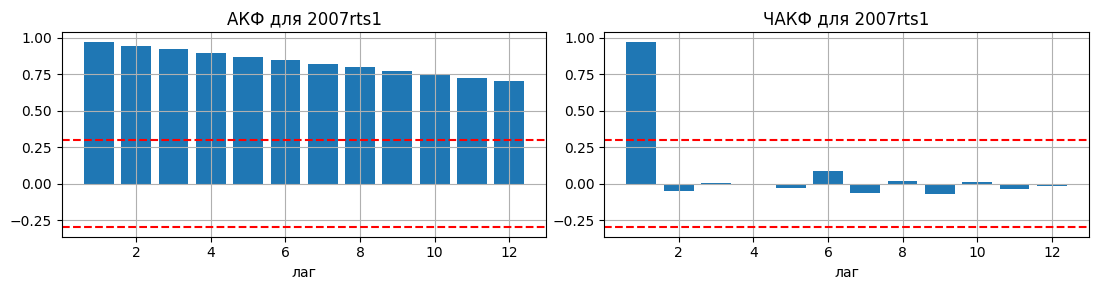

,1,2,3,4,5,6,7,8,9,10,11,12
ACF,0.0313,0.0197,-0.0372,0.0677,-0.1552,0.0590,-0.0147,0.0893,0.0216,0.0363,-0.0967,-0.0257
PACF,0.0313,0.0187,-0.0385,0.0699,-0.1594,0.0696,-0.0112,0.0753,0.0415,-0.0032,-0.0750,-0.0369


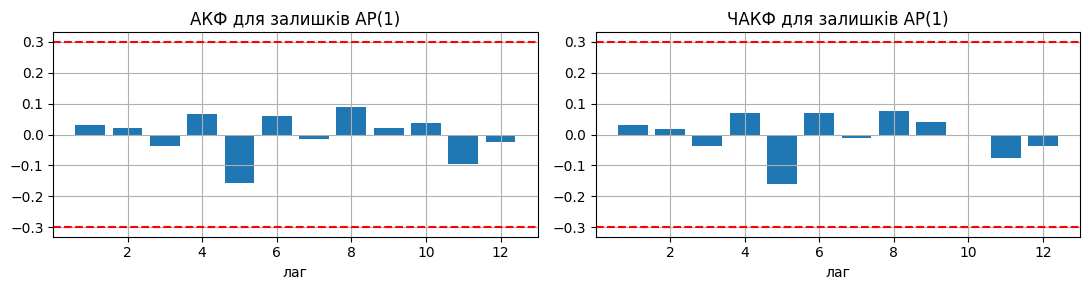

,1,2,3,4,5,6,7,8,9,10,11,12
SMA(5),0.9850,-0.1678,-0.1013,-0.0534,-0.0132,0.0254,-0.0103,-0.0295,-0.0476,-0.0342,-0.0459,-0.0104
SMA(10),0.9863,-0.1091,-0.0946,-0.0896,-0.0698,-0.0611,-0.0421,-0.0212,-0.0117,0.0117,0.0119,0.0082
EMA(5),0.9848,-0.1708,-0.1023,-0.0532,-0.0129,0.0453,0.0041,-0.0185,-0.0443,-0.0423,-0.0679,-0.0359
EMA(10),0.9862,-0.1244,-0.0906,-0.0703,-0.0538,-0.0396,-0.0367,-0.0267,-0.0211,-0.0109,-0.0162,-0.0051


In [67]:
t_rts2007 = analyze(rts2007, '2007rts1')

In [68]:
display(table1(t_rts2007))

,Група,Модель,R-squared,Sum squared resid,Akaike,Durbin-Watson
1,КС по залишках АР(p),АР(1),0.9719,163078.4431,9.3467,1.9313
2,КС по залишках АР(p),"АРКС(1,1) - КС системи (ma)",0.9719,162921.1207,9.3538,1.9924
3,КС по залишках АР(p),"АРКС(1,1) - власне просте КС, N=5",0.9815,99271.3733,8.8793,1.9193
4,КС по залишках АР(p),"АРКС(1,1) - власне просте КС, N=10",0.9754,128296.9303,9.1572,1.9907
5,КС по залишках АР(p),"АРКС(1,1) - власне експоненційне КС, N=5",0.9890,59098.1881,8.3607,1.9303
6,КС по залишках АР(p),"АРКС(1,1) - власне експоненційне КС, N=10",0.9813,97701.2580,8.8848,1.9756
7,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне просте КС по y, N=5",0.8825,659489.0744,10.7605,0.3702
8,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне просте КС по y, N=10",0.7118,1549831.4551,11.6361,0.1578
9,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне експоненційне КС по y, N=5",0.9486,283335.2625,9.9157,0.4629
10,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне експоненційне КС по y, N=10",0.8458,804765.8465,10.9807,0.2340


In [69]:
display(table2(t_rts2007))

,Група,Модель,Рівняння
1,КС по залишках АР(p),АР(1),"y(k) = 19,5101 + 0,9912·y(k−1)"
2,КС по залишках АР(p),"АРКС(1,1) - КС системи (ma)","y(k) = 21,1695 + 0,9903·y(k−1) + 0,0308·e(k−1) + e(k)"
3,КС по залишках АР(p),"АРКС(1,1) - власне просте КС, N=5","y(k) = 13,2896 + 0,9942·y(k−1) − 0,8608·ma(k−1) + ma(k)"
4,КС по залишках АР(p),"АРКС(1,1) - власне просте КС, N=10","y(k) = 25,8444 + 0,9879·y(k−1) − 0,7470·ma(k−1) + ma(k)"
5,КС по залишках АР(p),"АРКС(1,1) - власне експоненційне КС, N=5","y(k) = 16,7300 + 0,9925·y(k−1) − 0,6324·ma(k−1) + ma(k)"
6,КС по залишках АР(p),"АРКС(1,1) - власне експоненційне КС, N=10","y(k) = 20,8343 + 0,9904·y(k−1) − 0,7325·ma(k−1) + ma(k)"
7,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне просте КС по y, N=5","y(k) = −109,5900 − 0,9407·y(k−1) + ma(k) + 1,0000·ma(k−1)"
8,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне просте КС по y, N=10","y(k) = −306,6661 − 0,8367·y(k−1) + ma(k) + 1,0000·ma(k−1)"
9,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне експоненційне КС по y, N=5","y(k) = −61,1776 − 0,9667·y(k−1) + ma(k) + 1,0000·ma(k−1)"
10,"КС по y, підхід 1 (власні b_j)","АРКС(1,1) - власне експоненційне КС по y, N=10","y(k) = −189,6803 − 0,8987·y(k−1) + ma(k) + 1,0000·ma(k−1)"


**Найкраща модель для 2007rts1**

In [70]:
best_rts2007 = best_model(t_rts2007)
show(t_rts2007.loc[best_rts2007, 'res'], t_rts2007.loc[best_rts2007, 'Модель'])

АРКС(1,1) - власне експоненційне КС, N=5   (T = 242, k = 3)


,Coefficient,Std. Error,t-Statistic,Prob.
c,16.7300,14.0423,1.1914,0.2347
y(-1),0.9925,0.0071,140.6187,0.0000
ma(-1),-0.6324,0.0792,-7.9885,0.0000


,Значення
R-squared,0.9890
Adjusted R-squared,0.9889
S.E. of regression,15.7249
Sum squared resid,59098.1881
Log likelihood,-1008.6433
Mean dependent var,1986.1209
S.D. dependent var,149.1837
Akaike info criterion,8.3607
Schwarz criterion,8.4039
Durbin-Watson stat,1.9303


## Частина 3. Рівняння множинної регресії для rts1

$$
rts1=a_0+a_1 RTScr+a_2 RTSeu+a_3 RTSfn+a_4 RTSin+a_5 RTSmm+a_6 RTSog+a_7 RTStl
$$

### Кореляційна матриця

,rts1,RTScr,RTSeu,RTSfn,RTSin,RTSmm,RTSog,RTStl
rts1,1.0000,0.8480,0.6380,0.8790,0.8590,0.9290,0.9610,0.8230
RTScr,0.8480,1.0000,0.9290,0.9610,0.8980,0.8520,0.6820,0.9570
RTSeu,0.6380,0.9290,1.0000,0.8780,0.7940,0.6980,0.4120,0.8870
RTSfn,0.8790,0.9610,0.8780,1.0000,0.8280,0.8090,0.7390,0.9250
RTSin,0.8590,0.8980,0.7940,0.8280,1.0000,0.9440,0.7260,0.8860
RTSmm,0.9290,0.8520,0.6980,0.8090,0.9440,1.0000,0.8410,0.7980
RTSog,0.9610,0.6820,0.4120,0.7390,0.7260,0.8410,1.0000,0.6680
RTStl,0.8230,0.9570,0.8870,0.9250,0.8860,0.7980,0.6680,1.0000


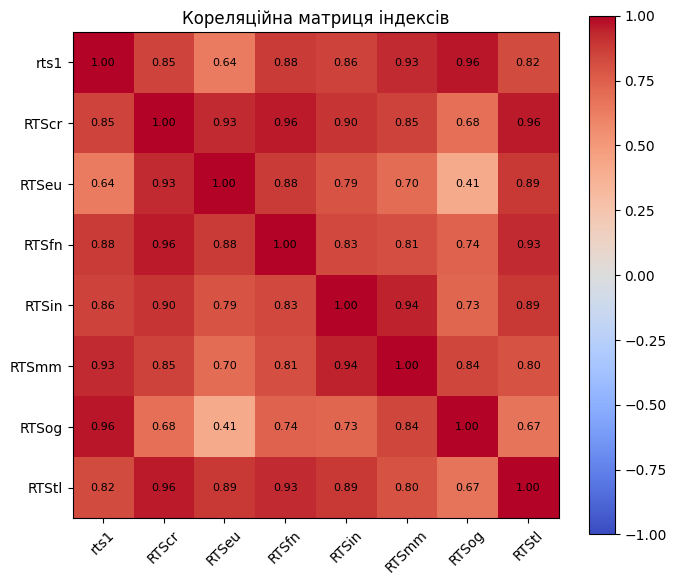

In [71]:
names = ['rts1', 'RTScr', 'RTSeu', 'RTSfn', 'RTSin', 'RTSmm', 'RTSog', 'RTStl']
idx = pd.DataFrame({n: np.loadtxt(f'Data/{n}.txt') for n in names})

corr = idx.corr()
display(corr.round(3))

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(names)), names, rotation=45)
plt.yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.title('Кореляційна матриця індексів')
plt.tight_layout()
plt.show()

Зв'язок сильний, якщо $|r|\ge 0{,}5$

In [72]:
r_y = corr['rts1'].drop('rts1')
selected = [x for x in r_y.index if abs(r_y[x]) >= 0.5]

display(r_y.round(3).to_frame('r(rts1, x)'))
print('Регресори з |r| >= 0,5:', selected)

,"r(rts1, x)"
RTScr,0.8480
RTSeu,0.6380
RTSfn,0.8790
RTSin,0.8590
RTSmm,0.9290
RTSog,0.9610
RTStl,0.8230


Регресори з |r| >= 0,5: ['RTScr', 'RTSeu', 'RTSfn', 'RTSin', 'RTSmm', 'RTSog', 'RTStl']


### Рівняння множинної регресії

In [73]:
X = pd.DataFrame({'c': 1.0, **{x: idx[x] for x in selected}})
eq = ls(idx['rts1'], X)
show(eq, 'rts1')


def mr_equation(res):
    s = 'rts1 = ' + ('−' if res['coef']['c'] < 0 else '') + num(res['coef']['c'])
    for col, v in res['coef'].drop('c').items():
        s += f" {'−' if v < 0 else '+'} {num(v)}·{col}"
    return s


print(mr_equation(eq))

rts1   (T = 178, k = 8)


,Coefficient,Std. Error,t-Statistic,Prob.
c,-59.2659,12.0244,-4.9288,0.0000
RTScr,-0.1857,0.1263,-1.4702,0.1434
RTSeu,0.0079,0.0563,0.1405,0.8884
RTSfn,0.7820,0.0380,20.5697,0.0000
RTSin,-0.1134,0.0557,-2.0359,0.0433
RTSmm,1.2493,0.0614,20.3432,0.0000
RTSog,4.1370,0.0724,57.1785,0.0000
RTStl,0.6523,0.0911,7.1599,0.0000


,Значення
R-squared,0.9993
Adjusted R-squared,0.9992
S.E. of regression,7.9607
Sum squared resid,10773.3253
Log likelihood,-617.7421
Mean dependent var,2043.5373
S.D. dependent var,289.9214
Akaike info criterion,7.0308
Schwarz criterion,7.1738
Durbin-Watson stat,0.4423


rts1 = −59,2659 − 0,1857·RTScr + 0,0079·RTSeu + 0,7820·RTSfn − 0,1134·RTSin + 1,2493·RTSmm + 4,1370·RTSog + 0,6523·RTStl


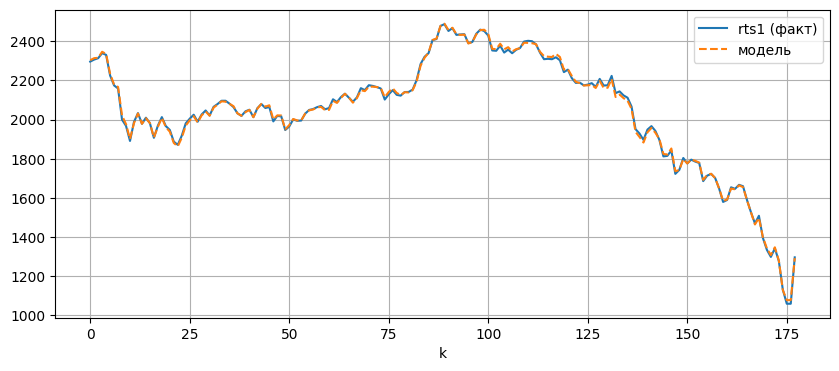

In [74]:
plt.figure(figsize=(10, 4))
plt.plot(idx['rts1'], label='rts1 (факт)')
plt.plot(idx['rts1'] - eq['resid'], '--', label='модель')
plt.xlabel('k')
plt.legend()
plt.grid()
plt.show()